# 実験9 (ex009): Shakespeare 次文字予測 MCLR ($N=10$ 非シャッフル自然 Non-IID, 200ラウンド)

論文 Figure 8(a,b,e,f) に基づき、長さ50文字セグメントの次文字予測タスク（$V=65, d=16,965$）を同一設定（$\alpha=0.003$）および最適設定（FedAvg $\alpha=0.1$, 2次系 $\alpha=0.01, \eta=1.0$）で比較します。

In [1]:
import os
import torch
import pandas as pd
from model import verify_batched_mclr_equivalence
from utils import (
    DEFAULT_SEEDS, load_and_partition_shakespeare, run_multiseed_shakespeare,
    plot_shakespeare_curves, plot_shakespeare_boxplot, plot_filtered_results,
)

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"使用デバイス: {device}")

使用デバイス: cuda


In [2]:
clients, packed_clients, X_train, y_train, X_test, y_test, vocab_size = load_and_partition_shakespeare(
    data_dir="../datasets", num_clients=10, train_ratio=0.75, seed=42, device=device
)
max_diff = verify_batched_mclr_equivalence(clients, packed_clients, tau=5, batch_size=100, lr=0.003, device=device)
print(f"Shakespeare train={X_train.shape}, test={X_test.shape}, vocab={vocab_size} | 並列SGD最大誤差: {max_diff:.3e}")

Shakespeare train=torch.Size([90000, 260]), test=torch.Size([30000, 260]), vocab=65 | 並列SGD最大誤差: 1.118e-08


In [3]:
configs_same = [
    {"name": "FedAvg",        "algo": "FedAvg",        "lr": 0.003},
    {"name": "FedSSO",        "algo": "FedSSO",        "lr": 0.003, "eta": 1.0},
    {"name": "FedSSO-NAQ",    "algo": "FedSSO-NAQ",    "lr": 0.003, "eta": 1.0, "mu": 0.30},
    {"name": "FedSSO-MoQ",    "algo": "FedSSO-MoQ",    "lr": 0.003, "eta": 1.0, "mu": 0.30},
    {"name": "FedSSO-AdaNAQ", "algo": "FedSSO-AdaNAQ", "lr": 0.003, "eta": 1.0, "max_mu": 0.40},
    {"name": "FedSSO-AdaMoQ", "algo": "FedSSO-AdaMoQ", "lr": 0.003, "eta": 1.0, "max_mu": 0.40},
    {"name": "FedSSO-LBFGS",  "algo": "FedSSO-LBFGS",  "lr": 0.003, "eta": 1.0, "m_size": 10},
    {"name": "FedSSO-LNAQ",   "algo": "FedSSO-LNAQ",   "lr": 0.003, "eta": 1.0, "max_mu": 0.40, "m_size": 10},
    {"name": "FedSSO-LMoQ",   "algo": "FedSSO-LMoQ",   "lr": 0.003, "eta": 1.0, "max_mu": 0.40, "m_size": 10},
    {"name": "FedSSO-MLNAQ",  "algo": "FedSSO-MLNAQ",  "lr": 0.003, "eta": 1.0, "max_mu": 0.40},
    {"name": "FedSSO-MLMoQ",  "algo": "FedSSO-MLMoQ",  "lr": 0.003, "eta": 1.0, "max_mu": 0.40},
]
configs_opt = [{"name": "FedAvg", "algo": "FedAvg", "lr": 0.1}] + [
    {**c, "lr": 0.01} for c in configs_same[1:]
]

sum_same, ps_same, curves_same = run_multiseed_shakespeare(
    configs_same, packed_clients, X_train, y_train, X_test, y_test, setting_tag="same",
    seeds=DEFAULT_SEEDS, rounds=200, save_log_dir="../datasets/ex009_shakespeare_mclr_logs",
    history_csv_path="../datasets/ex009_shakespeare_mclr_same_history.csv",
)
sum_opt, ps_opt, curves_opt = run_multiseed_shakespeare(
    configs_opt, packed_clients, X_train, y_train, X_test, y_test, setting_tag="opt",
    seeds=DEFAULT_SEEDS, rounds=200, save_log_dir="../datasets/ex009_shakespeare_mclr_logs",
    history_csv_path="../datasets/ex009_shakespeare_mclr_opt_history.csv",
)
sum_same.to_csv("../datasets/ex009_shakespeare_mclr_same_summary.csv", index=False)
ps_same.to_csv("../datasets/ex009_shakespeare_mclr_same_per_seed.csv", index=False)
sum_opt.to_csv("../datasets/ex009_shakespeare_mclr_opt_summary.csv", index=False)
ps_opt.to_csv("../datasets/ex009_shakespeare_mclr_opt_per_seed.csv", index=False)
sum_opt

,Setting,Algorithm,Comm_Per_Iter,Loss_Ave,Acc_Ave,Acc_Med,Acc_Best,Acc_Worst,Acc_Std,MaxAcc_Ave,Clip_Ave,Reset_Ave,Server_Time_ms,Server_Mem_MB,Bytes@0.30,Reach@0.20,Iter@0.20,Comm@0.20,Reach@0.25,Iter@0.25,Comm@0.25,Reach@0.30,Iter@0.30,Comm@0.30,Reach@0.32,Iter@0.32,Comm@0.32
0,opt,FedAvg,1.000,3.010307,0.226077,0.226517,0.227867,0.224100,0.001227,0.226103,0.0,0.0,0.007133,0.064716,27144000,10/10,90.6,90.6,0/10,NaN,NaN,0/10,NaN,NaN,0/10,NaN,NaN
1,opt,FedSSO,1.000,2.365646,0.359273,0.359400,0.362600,0.354067,0.002241,0.361420,0.3,1.5,7.915915,1098.171558,3922308,10/10,8.4,8.4,10/10,14.0,14.0,10/10,28.9,28.9,10/10,38.7,38.7
2,opt,FedSSO-NAQ,1.995,2.366072,0.357917,0.357900,0.361767,0.354067,0.002394,0.361633,0.2,2.2,7.833155,1098.300991,7817472,10/10,9.7,18.4,10/10,15.3,29.6,10/10,29.3,57.6,10/10,38.4,75.8
3,opt,FedSSO-MoQ,1.000,2.368483,0.358170,0.358283,0.360700,0.355500,0.001633,0.360493,0.3,1.1,7.954378,1098.365707,3990168,10/10,8.7,8.7,10/10,14.7,14.7,10/10,29.4,29.4,10/10,39.2,39.2
4,opt,FedSSO-AdaNAQ,1.995,2.366589,0.358340,0.358400,0.360667,0.356700,0.001170,0.361190,0.5,3.4,7.800128,1098.300991,7953192,10/10,11.4,21.8,10/10,16.4,31.8,10/10,29.8,58.6,10/10,41.5,82.0
5,opt,FedSSO-AdaMoQ,1.000,2.370906,0.358237,0.358400,0.360333,0.355500,0.001439,0.360543,0.2,1.3,7.865294,1098.365707,3868020,10/10,8.2,8.2,10/10,14.0,14.0,10/10,28.5,28.5,10/10,39.7,39.7
6,opt,FedSSO-LBFGS,1.000,2.354223,0.362770,0.363333,0.365667,0.358533,0.002123,0.364793,0.5,1.3,1.554330,1.553192,1560780,10/10,5.3,5.3,10/10,8.0,8.0,10/10,11.5,11.5,10/10,14.3,14.3
7,opt,FedSSO-LNAQ,1.995,2.358903,0.360627,0.360633,0.363833,0.357667,0.001623,0.363823,0.9,2.9,1.425954,1.682625,4587336,10/10,8.2,15.4,10/10,11.2,21.4,10/10,17.4,33.8,10/10,22.7,44.4
8,opt,FedSSO-LMoQ,1.000,2.363765,0.359983,0.360767,0.362467,0.354067,0.002352,0.362863,0.3,1.4,1.141982,1.747341,1764360,10/10,5.5,5.5,10/10,8.5,8.5,10/10,13.0,13.0,10/10,16.7,16.7
9,opt,FedSSO-MLNAQ,1.995,2.420941,0.344720,0.343567,0.352800,0.336467,0.005434,0.346310,63.3,4.5,0.520183,0.517731,5998824,10/10,13.0,25.0,10/10,17.1,33.2,10/10,22.6,44.2,10/10,28.9,56.8


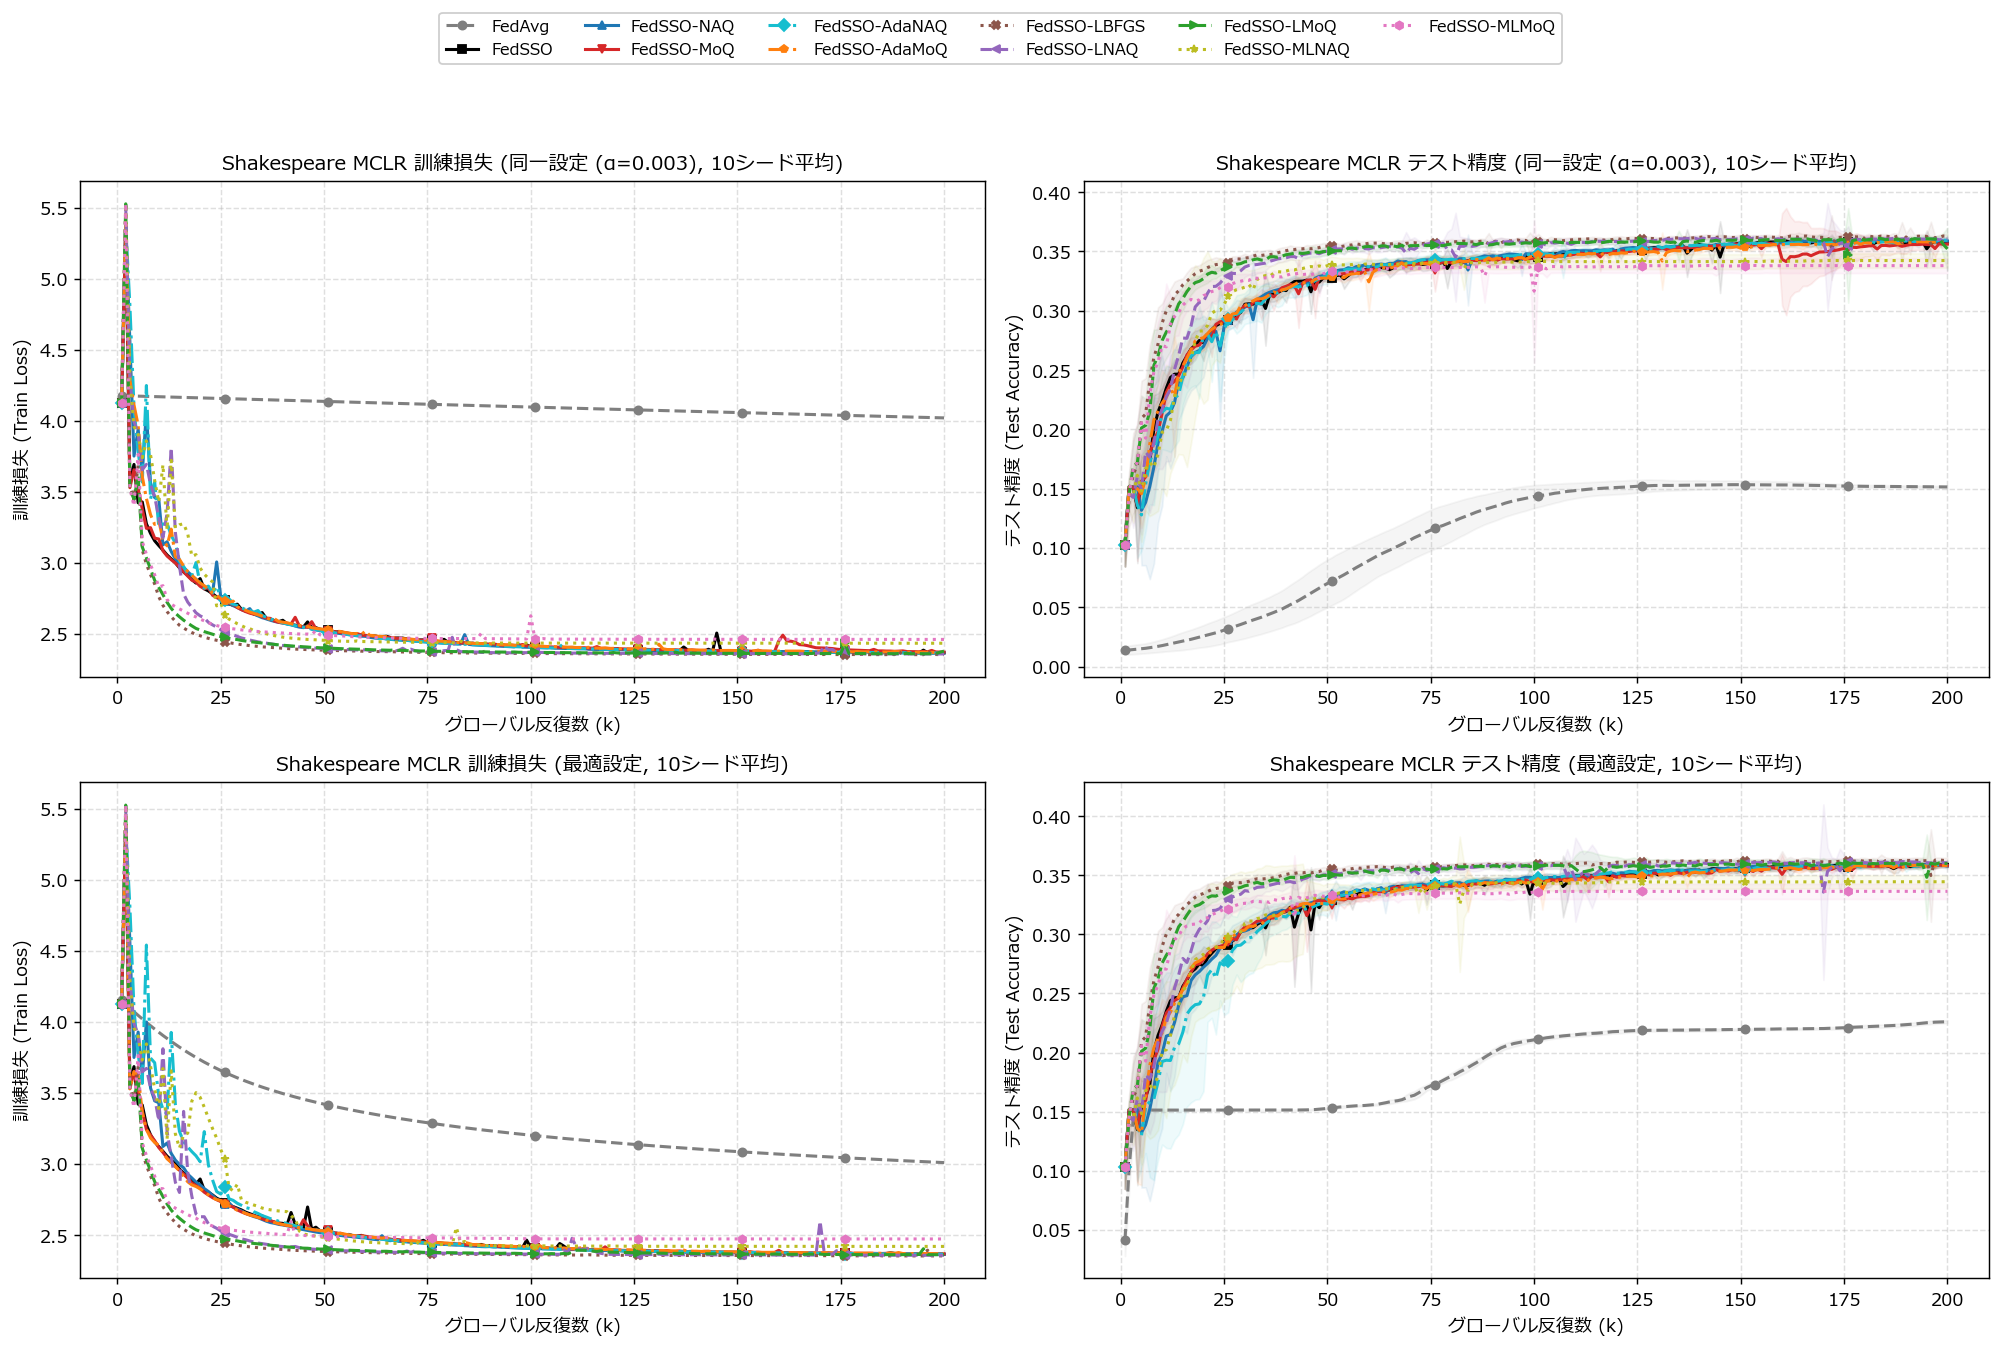

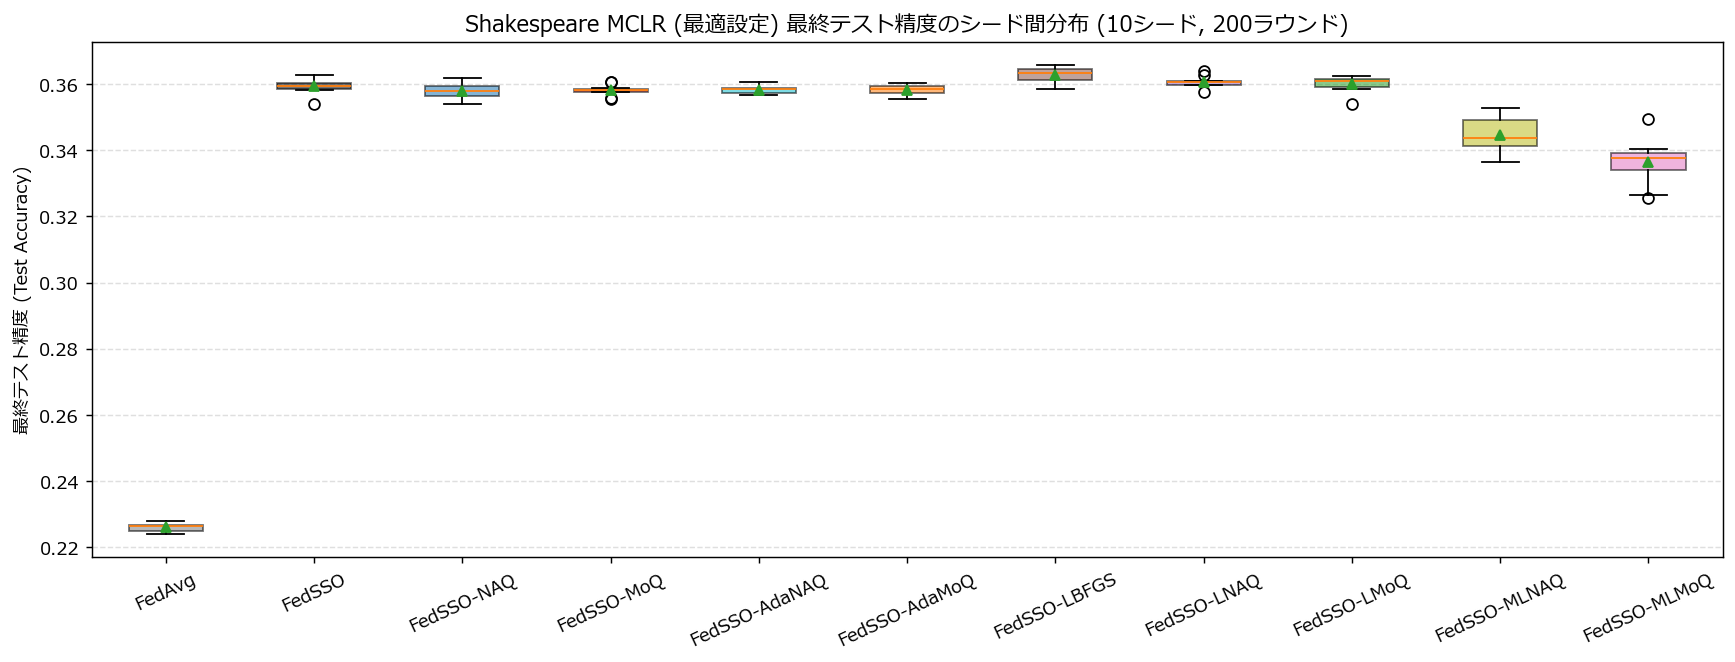

In [4]:
os.makedirs("../report/img", exist_ok=True)
plot_shakespeare_curves(curves_same, curves_opt, save_path="../report/img/ex009_shakespeare_mclr_curves.png")
plot_shakespeare_boxplot(ps_opt, save_path="../report/img/ex009_shakespeare_mclr_boxplot.png")

## 特定のシード値・アルゴリズムに絞ったグラフ表示

保存済みの全履歴 CSV（`../datasets/ex009_shakespeare_mclr_opt_history.csv`）から任意のアルゴリズム・シード値だけを指定して再描画できます。 `SELECTED_SEEDS = None` のときは全シード平均のみを自動表示・出力します。

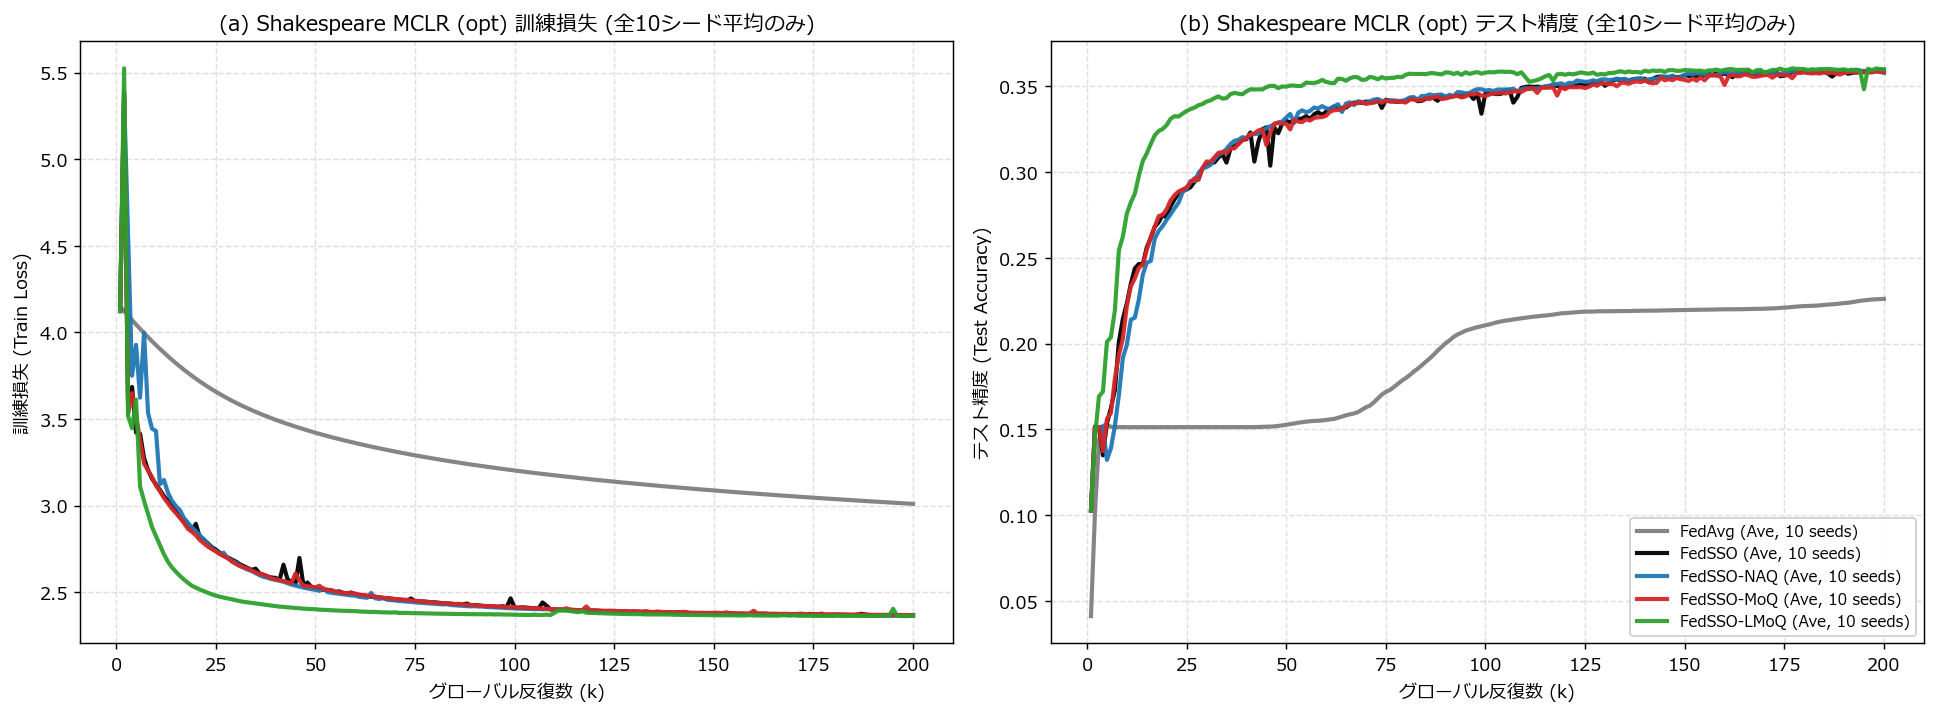

,Algorithm,Seeds,Round,Comm_Round,Train_Loss_Ave,Test_Acc_Ave
0,FedAvg,10,200,200.0,3.010307,0.226077
1,FedSSO,10,200,200.0,2.365646,0.359273
2,FedSSO-NAQ,10,200,399.0,2.366072,0.357917
3,FedSSO-MoQ,10,200,200.0,2.368483,0.358170
4,FedSSO-LMoQ,10,200,200.0,2.363765,0.359983


In [5]:
# ここを変更して特定のシード値・アルゴリズムのグラフを表示
# 利用可能なアルゴリズム:
#   ["FedAvg", "FedSSO", "FedSSO-NAQ", "FedSSO-MoQ", "FedSSO-AdaNAQ", "FedSSO-AdaMoQ",
#    "FedSSO-LBFGS", "FedSSO-LNAQ", "FedSSO-LMoQ", "FedSSO-MLNAQ", "FedSSO-MLMoQ"]
#   None を指定すると全手法が対象になります
# 利用可能なシード値: [42, 43, 44, 45, 46, 47, 48, 49, 50, 51] (None で全シード対象)
SELECTED_ALGOS = ["FedAvg", "FedSSO", "FedSSO-NAQ", "FedSSO-MoQ", "FedSSO-LMoQ"]
SELECTED_SEEDS = None       # None で全10シード対象（例: [42, 46] で特定シードに絞り込み）
X_AXIS_MODE = "round"       # "round" (反復数) または "comm" (累積通信ラウンド数)
SHOW_MEAN_CURVE = True      # 複数シード指定時に平均太線を重ね描きするか
PLOT_MEAN_ONLY = "auto"     # "auto": SELECTED_SEEDS=None 時に平均線のみ描画 / True: 平均のみ / False: 個別シードも描画
TABLE_MEAN_ONLY = "auto"    # "auto": SELECTED_SEEDS=None 時に平均のみの行を出力 / True: 平均のみ / False: シード別に出力

filtered_df = plot_filtered_results(
    selected_algos=SELECTED_ALGOS,
    selected_seeds=SELECTED_SEEDS,
    setting_tag="opt",
    history_csv_path="../datasets/ex009_shakespeare_mclr_opt_history.csv",
    log_dir="../datasets/ex009_shakespeare_mclr_logs",
    x_axis=X_AXIS_MODE,
    show_mean=SHOW_MEAN_CURVE,
    plot_mean_only=PLOT_MEAN_ONLY,
    table_mean_only=TABLE_MEAN_ONLY,
)
filtered_df